Using Colab cache for faster access to the 'leapgestrecog' dataset.
Dataset downloaded to: /kaggle/input/leapgestrecog
Loading and processing images...
Total images loaded: 20000
Total classes: 10
Building the model...
Training the CNN... (This takes about 1-2 minutes)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 105s 208ms/step - accuracy: 0.9337 - loss: 0.2128 - val_accuracy: 0.9940 - val_loss: 0.0160
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 135s 195ms/step - accuracy: 0.9974 - loss: 0.0096 - val_accuracy: 0.9998 - val_loss: 0.0014
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 144s 198ms/step - accuracy: 0.9998 - loss: 7.4533e-04 - val_accuracy: 0.9995 - val_loss: 0.0022
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 99s 197ms/step - accuracy: 1.0000 - loss: 6.3033e-05 - val_accuracy: 0.9995 - val_loss: 0.0026
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 99s 198ms/step - accuracy: 1.0000 - loss: 2.5883e-05 - val_accuracy: 0.9995 - val_loss: 0.0024
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - accuracy: 0.9995 - loss: 0.0024

Model Accuracy: 99.95%


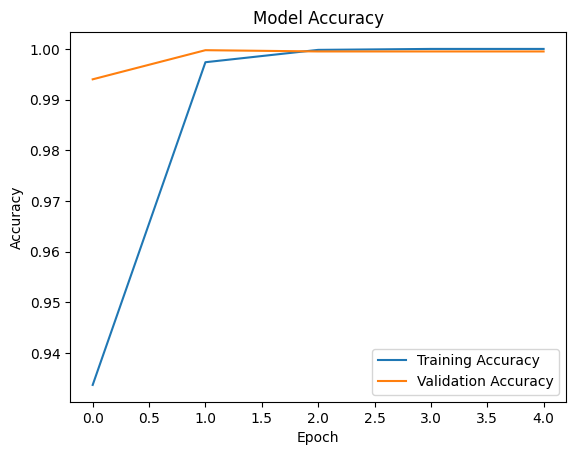

In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
import kagglehub

# 1. Download the dataset using KaggleHub
print("Downloading Hand Gesture dataset... (This might take a minute)")
path = kagglehub.dataset_download("gti-upm/leapgestrecog")
print("Dataset downloaded to:", path)

# 2. Set up paths and load images
data_dir = os.path.join(path, 'leapGestRecog')

images = []
labels = []
label_names = []

# We will limit to 200 images per gesture to save Colab RAM and time
limit_per_class = 200
img_size = 64

print("Loading and processing images...")
for subject_folder in os.listdir(data_dir):
    subject_path = os.path.join(data_dir, subject_folder)
    if not os.path.isdir(subject_path): continue

    for gesture_folder in os.listdir(subject_path):
        gesture_path = os.path.join(subject_path, gesture_folder)
        if not os.path.isdir(gesture_path): continue

        # Store label names (e.g., '01_palm', '02_l')
        if gesture_folder not in label_names:
            label_names.append(gesture_folder)

        label_index = label_names.index(gesture_folder)
        count = 0

        for img_name in os.listdir(gesture_path):
            if count >= limit_per_class: break
            img_path = os.path.join(gesture_path, img_name)

            try:
                # Read image and resize
                img = cv2.imread(img_path)
                img = cv2.resize(img, (img_size, img_size))
                images.append(img)
                labels.append(label_index)
                count += 1
            except:
                continue

# Convert to numpy arrays and normalize
X = np.array(images) / 255.0
y = np.array(labels)

print(f"Total images loaded: {len(X)}")
print(f"Total classes: {len(label_names)}")

# 3. Split into Train and Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Build the CNN Model
print("Building the model...")
model = tf.keras.models.Sequential([
    # Convolutional layers to extract features
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(img_size, img_size, 3)),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Flatten the result before passing to dense layers
    tf.keras.layers.Flatten(),

    # Dense layers for classification
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(len(label_names), activation='softmax') # Output layer
])

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# 5. Train the model
print("Training the CNN... (This takes about 1-2 minutes)")
history = model.fit(X_train, y_train, epochs=5, validation_data=(X_test, y_test))

# 6. Evaluate and Plot
loss, accuracy = model.evaluate(X_test, y_test)
print(f"\nModel Accuracy: {accuracy * 100:.2f}%")

# Plot training history
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()